# Deep Learning on a Data Diet. Эксперименты по статье

## 0. Experiment setup and preparation

In [15]:
import os
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet18
from tqdm.auto import tqdm

import json
import platform

In [10]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
DATA_ROOT = './data'
NUM_CLASSES = 10
BATCH_SIZE = 128
TRAIN_SIZE = 50000
STEPS_PER_EPOCH = TRAIN_SIZE // BATCH_SIZE

NUM_SCORE_RUNS = 10
SCORE_MAX_EPOCHS = 20
SCORE_EPOCHS = [1, 2, 5, 10, 20]
SCORE_SEEDS = [run * 1000 + 42 for run in range(NUM_SCORE_RUNS)]

TARGET_SCORE_EPOCH = 10
KEEP_FRACTIONS = [1.0, 0.9, 0.7, 0.5, 0.3]
STRATEGIES = ['el2n_highest', 'el2n_lowest', 'random']
EVAL_SEEDS = [101, 202, 303]
RETRAIN_EPOCHS_EQUIV = 50
TOTAL_STEPS = RETRAIN_EPOCHS_EQUIV * STEPS_PER_EPOCH

SCORES_CKPT = 'el2n_checkpoint.pt'
SCORES_FINAL = 'el2n_scores_all_epochs.pt'
STEP2_CKPT = 'step2_checkpoint.pt'
STEP2_RESULTS = 'step2_retraining_results.pt'

assert not set(SCORE_SEEDS) & set(EVAL_SEEDS)
print(DEVICE, torch.cuda.get_device_name(0) if USE_AMP else '')
print(f"{STEPS_PER_EPOCH} steps per full-data epoch, {TOTAL_STEPS} steps per retraining run")

cuda NVIDIA GeForce RTX 3070 Ti
390 steps per full-data epoch, 19500 steps per retraining run


In [11]:
def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def amp():
    return torch.amp.autocast('cuda', enabled=USE_AMP)


def build_cifar_resnet18():
    model = resnet18(num_classes=NUM_CLASSES)
    model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    model.maxpool = nn.Identity()
    return model


def build_optimizer(model):
    return optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4, nesterov=True)


def load_cifar10_split(train):
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
    ])
    dataset = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=train, download=True, transform=transform)
    data = torch.stack([img for img, _ in dataset]).to(DEVICE)
    targets = torch.tensor(dataset.targets, dtype=torch.long, device=DEVICE)
    return data, targets


def gpu_augment(x, pad=4):
    B, C, H, W = x.shape
    xp = F.pad(x, (pad, pad, pad, pad))
    top = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    left = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    rows = (top[:, None] + torch.arange(H, device=x.device))[:, None, :, None]
    cols = (left[:, None] + torch.arange(W, device=x.device))[:, None, None, :]
    b = torch.arange(B, device=x.device)[:, None, None, None]
    c = torch.arange(C, device=x.device)[None, :, None, None]
    out = xp[b, c, rows, cols]
    flip = torch.rand(B, device=x.device) < 0.5
    return torch.where(flip[:, None, None, None], out.flip(3), out)


@torch.no_grad()
def evaluate_accuracy(model, data, targets, batch_size=500):
    model.eval()
    correct = 0
    for i in range(0, data.size(0), batch_size):
        with amp():
            preds = model(data[i:i + batch_size]).argmax(dim=1)
        correct += (preds == targets[i:i + batch_size]).sum().item()
    return 100.0 * correct / data.size(0)

In [4]:
TRAIN_DATA, TRAIN_TARGETS = load_cifar10_split(True)
TEST_DATA, TEST_TARGETS = load_cifar10_split(False)
print(TRAIN_DATA.shape, TRAIN_TARGETS.shape, TEST_DATA.shape, TEST_TARGETS.shape)

torch.Size([50000, 3, 32, 32]) torch.Size([50000]) torch.Size([10000, 3, 32, 32]) torch.Size([10000])


## 1. Computing Early EL2N Scores

In [5]:
@torch.no_grad()
def compute_el2n_scores(model, data, targets, batch_size=500):
    model.eval()
    chunks = []
    for i in range(0, data.size(0), batch_size):
        x = data[i:i + batch_size]
        y = targets[i:i + batch_size]
        with amp():
            logits = model(x)
        probs = torch.softmax(logits.float(), dim=1)
        one_hot = F.one_hot(y, num_classes=NUM_CLASSES).float()
        chunks.append(torch.norm(probs - one_hot, p=2, dim=1).cpu())
    return torch.cat(chunks)


def compute_el2n_single_run(seed, train_data, train_targets, epoch_bar):
    seed_everything(seed)
    model = build_cifar_resnet18().to(DEVICE)
    optimizer = build_optimizer(model)
    criterion = nn.CrossEntropyLoss()
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    n = train_data.size(0)
    run_scores = {}
    epoch_bar.reset(total=SCORE_MAX_EPOCHS)
    for epoch in range(1, SCORE_MAX_EPOCHS + 1):
        model.train()
        perm = torch.randperm(n, device=DEVICE)
        loss_sum = torch.zeros((), device=DEVICE)
        for i in range(0, n - BATCH_SIZE + 1, BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            inputs = gpu_augment(train_data[idx])
            targets = train_targets[idx]
            optimizer.zero_grad(set_to_none=True)
            with amp():
                loss = criterion(model(inputs), targets)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            loss_sum += loss.detach()
        epoch_bar.set_postfix(loss=f"{loss_sum.item() / STEPS_PER_EPOCH:.4f}")
        epoch_bar.update(1)
        if epoch in SCORE_EPOCHS:
            run_scores[epoch] = compute_el2n_scores(model, train_data, train_targets)
    return run_scores


def run_step1_scoring(train_data, train_targets):
    if os.path.exists(SCORES_CKPT):
        state = torch.load(SCORES_CKPT, map_location='cpu', weights_only=False)
        assert state['seeds'] == SCORE_SEEDS, "Scoring checkpoint was made with different seeds - delete it"
    else:
        state = {'seeds': SCORE_SEEDS, 'per_run': {ep: [] for ep in SCORE_EPOCHS}}
    done = len(state['per_run'][SCORE_EPOCHS[0]])
    run_bar = tqdm(total=NUM_SCORE_RUNS, initial=done, desc="Step 1: scoring runs")
    epoch_bar = tqdm(total=SCORE_MAX_EPOCHS, desc="Epochs", leave=False)
    durations = []
    for run in range(done, NUM_SCORE_RUNS):
        start = time.time()
        run_scores = compute_el2n_single_run(SCORE_SEEDS[run], train_data, train_targets, epoch_bar)
        for ep in SCORE_EPOCHS:
            state['per_run'][ep].append(run_scores[ep])
        torch.save(state, SCORES_CKPT)
        durations.append(time.time() - start)
        remaining = NUM_SCORE_RUNS - run - 1
        run_bar.update(1)
        run_bar.set_postfix(last_min=f"{durations[-1] / 60:.1f}", eta_min=f"{np.mean(durations) * remaining / 60:.0f}")
    epoch_bar.close()
    run_bar.close()
    scores_dict = {ep: torch.stack(state['per_run'][ep]).mean(dim=0) for ep in SCORE_EPOCHS}
    torch.save(scores_dict, SCORES_FINAL)
    return scores_dict, state['per_run']

In [6]:
SCORES_DICT, PER_RUN_SCORES = run_step1_scoring(TRAIN_DATA, TRAIN_TARGETS)

for ep in SCORE_EPOCHS:
    s = SCORES_DICT[ep]
    print(f"epoch {ep:>2} | mean {s.mean():.4f} | std {s.std():.4f} | min {s.min():.4f} | max {s.max():.4f}")

Step 1: scoring runs:   0%|          | 0/10 [00:00<?, ?it/s]

Epochs:   0%|          | 0/20 [00:00<?, ?it/s]

epoch  1 | mean 0.7860 | std 0.2127 | min 0.0773 | max 1.3154
epoch  2 | mean 0.6404 | std 0.2966 | min 0.0112 | max 1.3680
epoch  5 | mean 0.4002 | std 0.3330 | min 0.0000 | max 1.4081
epoch 10 | mean 0.3055 | std 0.3113 | min 0.0000 | max 1.4096
epoch 20 | mean 0.2426 | std 0.2833 | min 0.0000 | max 1.3970


## 2. Data Pruning and Retraining

In [12]:
def get_pruned_indices(scores, keep_fraction, strategy, seed):
    n = len(scores)
    k = int(round(n * keep_fraction))
    if keep_fraction >= 1.0:
        return torch.arange(n)
    if strategy == 'el2n_highest':
        return torch.argsort(scores, descending=True)[:k]
    if strategy == 'el2n_lowest':
        return torch.argsort(scores, descending=False)[:k]
    if strategy == 'random':
        g = torch.Generator()
        g.manual_seed(seed)
        return torch.randperm(n, generator=g)[:k]
    raise ValueError(strategy)


def train_on_subset(indices, train_data, train_targets, test_data, test_targets, seed, total_steps=TOTAL_STEPS):
    seed_everything(seed)
    indices = indices.to(DEVICE)
    sub_data = train_data[indices]
    sub_targets = train_targets[indices]
    n = sub_data.size(0)
    model = build_cifar_resnet18().to(DEVICE)
    optimizer = build_optimizer(model)
    milestones = [int(0.3 * total_steps), int(0.6 * total_steps), int(0.8 * total_steps)]
    scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=milestones, gamma=0.2)
    criterion = nn.CrossEntropyLoss()
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    model.train()
    step = 0
    pbar = tqdm(total=total_steps, desc="Retraining", leave=False, mininterval=2)
    while step < total_steps:
        perm = torch.randperm(n, device=DEVICE)
        for i in range(0, n - BATCH_SIZE + 1, BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            inputs = gpu_augment(sub_data[idx])
            targets = sub_targets[idx]
            optimizer.zero_grad(set_to_none=True)
            with amp():
                loss = criterion(model(inputs), targets)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            step += 1
            pbar.update(1)
            if step % 200 == 0:
                pbar.set_postfix(loss=f"{loss.item():.3f}", lr=f"{scheduler.get_last_lr()[0]:.4f}")
            if step >= total_steps:
                break
    pbar.close()
    return evaluate_accuracy(model, test_data, test_targets)


def run_step2(scores_dict, train_data, train_targets, test_data, test_targets):
    scores = scores_dict[TARGET_SCORE_EPOCH]
    config = {'score_epoch': TARGET_SCORE_EPOCH, 'total_steps': TOTAL_STEPS, 'batch_size': BATCH_SIZE}
    if os.path.exists(STEP2_CKPT):
        state = torch.load(STEP2_CKPT, map_location='cpu', weights_only=False)
        assert state['config'] == config, "Step 2 checkpoint was made with different settings - delete it"
        results = state['results']
    else:
        results = {s: {} for s in STRATEGIES}

    jobs = []
    for frac in KEEP_FRACTIONS:
        for seed in EVAL_SEEDS:
            if frac >= 1.0:
                jobs.append(('full', frac, seed))
            else:
                jobs.extend((s, frac, seed) for s in STRATEGIES)

    bar = tqdm(total=len(jobs), desc="Step 2: retraining runs")
    durations = []
    for kind, frac, seed in jobs:
        keys = STRATEGIES if kind == 'full' else [kind]
        if all(seed in results[k].get(frac, {}) for k in keys):
            bar.update(1)
            continue
        start = time.time()
        strategy = 'random' if kind == 'full' else kind
        indices = get_pruned_indices(scores, frac, strategy, seed)
        acc = train_on_subset(indices, train_data, train_targets, test_data, test_targets, seed)
        for k in keys:
            results[k].setdefault(frac, {})[seed] = acc
        torch.save({'results': results, 'config': config}, STEP2_CKPT)
        durations.append(time.time() - start)
        remaining = len(jobs) - bar.n - 1
        bar.update(1)
        bar.set_postfix(last=f"{kind} keep={frac} acc={acc:.2f}", eta_min=f"{np.mean(durations) * remaining / 60:.0f}")
        tqdm.write(f"{kind:<13} keep={frac:.1f} seed={seed} test_acc={acc:.2f}% ({durations[-1] / 60:.1f} min)")
    bar.close()
    torch.save(results, STEP2_RESULTS)
    return results

In [14]:
STEP2_RESULTS_DICT = run_step2(SCORES_DICT, TRAIN_DATA, TRAIN_TARGETS, TEST_DATA, TEST_TARGETS)

Step 2: retraining runs:   0%|          | 0/39 [00:00<?, ?it/s]

Retraining:   0%|          | 0/19500 [00:00<?, ?it/s]

full          keep=1.0 seed=101 test_acc=93.88% (12.4 min)


Retraining:   0%|          | 0/19500 [00:00<?, ?it/s]

full          keep=1.0 seed=202 test_acc=93.66% (14.6 min)


...

el2n_highest  keep=0.3 seed=303 test_acc=86.02% (8.7 min)


Retraining:   0%|          | 0/19500 [00:00<?, ?it/s]

el2n_lowest   keep=0.3 seed=303 test_acc=79.77% (8.8 min)


Retraining:   0%|          | 0/19500 [00:00<?, ?it/s]

random        keep=0.3 seed=303 test_acc=89.47% (8.9 min)


In [16]:
def build_summary(results):
    rows = []
    for frac in KEEP_FRACTIONS:
        row = {'keep_fraction': frac, 'pruned_fraction': round(1 - frac, 4)}
        for s in STRATEGIES:
            accs = list(results[s][frac].values())
            row[f'{s}_mean'] = float(np.mean(accs))
            row[f'{s}_std'] = float(np.std(accs, ddof=1)) if len(accs) > 1 else 0.0
            row[f'{s}_n'] = len(accs)
        rows.append(row)
    return pd.DataFrame(rows)


def plot_summary(df, path='step2_pruning_curve.png'):
    full = df[df['keep_fraction'] == 1.0].iloc[0]
    sub = df[df['keep_fraction'] < 1.0]
    x = sub['pruned_fraction'] * 100
    styles = {
        'el2n_highest': ('o-', '#1f77b4', 'EL2N: keep hardest (paper method)'),
        'el2n_lowest': ('s--', '#d62728', 'EL2N: keep easiest'),
        'random': ('^-', '#7f7f7f', 'Random subset'),
    }
    fig, ax = plt.subplots(figsize=(9, 6), dpi=150)
    ax.axhline(full['random_mean'], color='#7f3fbf', linestyle='--', linewidth=2, label='Full dataset (mean)')
    ax.axhspan(full['random_mean'] - full['random_std'], full['random_mean'] + full['random_std'], color='#7f3fbf', alpha=0.15)
    for s, (fmt, color, label) in styles.items():
        ax.errorbar(x, sub[f'{s}_mean'], yerr=sub[f'{s}_std'], fmt=fmt, color=color, label=label, capsize=4, linewidth=2)
    ax.set_title('CIFAR-10 + ResNet-18: test accuracy vs. fraction of data pruned (EL2N, epoch 10)')
    ax.set_xlabel('Dataset pruned (%)')
    ax.set_ylabel('Final test accuracy (%)')
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='lower left')
    fig.tight_layout()
    fig.savefig(path)
    plt.show()

 keep_fraction  pruned_fraction  el2n_highest_mean  el2n_highest_std  el2n_highest_n  el2n_lowest_mean  el2n_lowest_std  el2n_lowest_n  random_mean  random_std  random_n
           1.0              0.0              93.66              0.22               3             93.66             0.22              3        93.66        0.22         3
           0.9              0.1              93.73              0.21               3             91.27             0.10              3        93.31        0.42         3
           0.7              0.3              93.78              0.18               3             87.36             0.08              3        92.47        0.54         3
           0.5              0.5              93.74              0.17               3             83.91             0.20              3        91.32        0.06         3
           0.3              0.7              84.06              1.72               3             79.95             0.19              3        89.41   

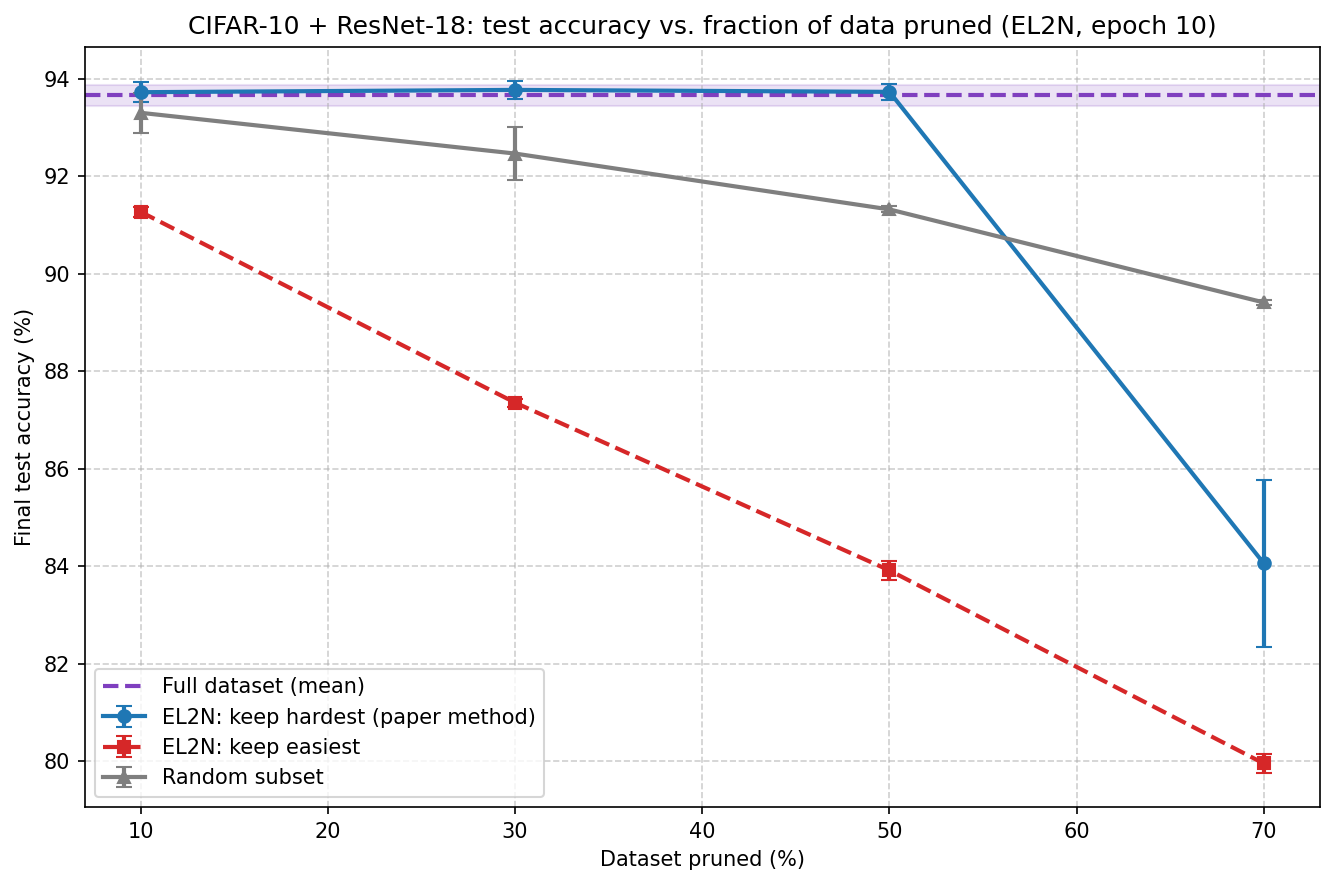

In [17]:
SUMMARY = build_summary(STEP2_RESULTS_DICT)
SUMMARY.to_csv('step2_summary.csv', index=False)
print(SUMMARY.round(2).to_string(index=False))
plot_summary(SUMMARY)

## 3. Score Epoch Ablation

In [18]:
needed = ['TRAIN_DATA', 'TRAIN_TARGETS', 'TEST_DATA', 'TEST_TARGETS', 'train_on_subset', 'get_pruned_indices',
          'compute_el2n_scores', 'run_step1_scoring', 'gpu_augment', 'build_cifar_resnet18', 'build_optimizer',
          'seed_everything', 'amp']
missing = [name for name in needed if name not in globals()]
assert not missing, f"Run cells 1-4 and 6 of the first notebook first. Missing: {missing}"

if 'SCORES_DICT' not in globals() or 'PER_RUN_SCORES' not in globals():
    assert os.path.exists(SCORES_CKPT) and os.path.exists(SCORES_FINAL), "Step 1 is not finished"
    SCORES_DICT, PER_RUN_SCORES = run_step1_scoring(TRAIN_DATA, TRAIN_TARGETS)

if 'STEP2_RESULTS_DICT' not in globals():
    assert os.path.exists(STEP2_RESULTS), "Step 2 is not finished"
    STEP2_RESULTS_DICT = torch.load(STEP2_RESULTS, weights_only=False)

CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
COLORS = {'el2n': '#1f77b4', 'forget': '#ff7f0e', 'random': '#7f7f7f', 'full': '#7f3fbf', 'lowest': '#d62728'}
print("ready | retrain steps per run:", TOTAL_STEPS, "| eval seeds:", EVAL_SEEDS)

ready | retrain steps per run: 19500 | eval seeds: [101, 202, 303]


In [19]:
def mean_std(values):
    values = [float(v) for v in values]
    return float(np.mean(values)), (float(np.std(values, ddof=1)) if len(values) > 1 else 0.0)


def spearman(a, b):
    ra = pd.Series(a.numpy()).rank()
    rb = pd.Series(b.numpy()).rank()
    return float(ra.corr(rb))


def step2_acc(strategy, frac, seed):
    return STEP2_RESULTS_DICT.get(strategy, {}).get(frac, {}).get(seed)


def make_job(indices, targets, seed):
    return dict(indices=indices, train_data=TRAIN_DATA, train_targets=targets,
                test_data=TEST_DATA, test_targets=TEST_TARGETS, seed=seed)


def load_store(path, config):
    if os.path.exists(path):
        state = torch.load(path, map_location='cpu', weights_only=False)
        assert state['config'] == config, f"{path} was made with different settings - move it away"
        return state['results']
    return {}


def run_jobs(jobs, path, config, desc, preset=None):
    results = load_store(path, config)
    if preset:
        for key, value in preset.items():
            results.setdefault(key, value)
    bar = tqdm(total=len(jobs), desc=desc)
    durations = []
    for key, kwargs in jobs:
        if key in results:
            bar.update(1)
            continue
        start = time.time()
        acc = train_on_subset(**kwargs)
        results[key] = acc
        torch.save({'results': results, 'config': config}, path)
        durations.append(time.time() - start)
        remaining = len(jobs) - bar.n - 1
        bar.update(1)
        bar.set_postfix(last=f"{acc:.2f}", eta_min=f"{np.mean(durations) * remaining / 60:.0f}")
        tqdm.write(f"{desc} | {key} | test_acc={acc:.2f}% ({durations[-1] / 60:.1f} min)")
    bar.close()
    torch.save({'results': results, 'config': config}, path)
    return results


def finish_figure(fig, path):
    fig.tight_layout()
    fig.savefig(path)
    plt.show()

In [20]:
ABL_KEEP = 0.5
ABL_EPOCHS = [1, 2, 5, 10, 20]
ABL_PATH = 'step3_epoch_ablation.pt'
ABL_CONFIG = {'total_steps': TOTAL_STEPS, 'keep': ABL_KEEP, 'target': TARGET_SCORE_EPOCH}

assert all(ep in SCORES_DICT for ep in ABL_EPOCHS)

abl_jobs = []
abl_preset = {}
for seed in EVAL_SEEDS:
    for ep in ABL_EPOCHS:
        key = ('el2n_highest', ep, seed)
        indices = get_pruned_indices(SCORES_DICT[ep], ABL_KEEP, 'el2n_highest', seed)
        abl_jobs.append((key, make_job(indices, TRAIN_TARGETS, seed)))
        reused = step2_acc('el2n_highest', ABL_KEEP, seed)
        if ep == TARGET_SCORE_EPOCH and reused is not None:
            abl_preset[key] = reused

ABL_RESULTS = run_jobs(abl_jobs, ABL_PATH, ABL_CONFIG, 'Step 3: score-epoch ablation', abl_preset)

Step 3: score-epoch ablation:   0%|          | 0/15 [00:00<?, ?it/s]

Retraining:   0%|          | 0/19500 [00:00<?, ?it/s]

Step 3: score-epoch ablation | ('el2n_highest', 1, 101) | test_acc=89.03% (8.9 min)


Retraining:   0%|          | 0/19500 [00:00<?, ?it/s]

Step 3: score-epoch ablation | ('el2n_highest', 2, 101) | test_acc=91.72% (9.0 min)


...

Step 3: score-epoch ablation | ('el2n_highest', 2, 303) | test_acc=91.84% (8.7 min)


Retraining:   0%|          | 0/19500 [00:00<?, ?it/s]

Step 3: score-epoch ablation | ('el2n_highest', 5, 303) | test_acc=93.28% (8.8 min)


Retraining:   0%|          | 0/19500 [00:00<?, ?it/s]

Step 3: score-epoch ablation | ('el2n_highest', 20, 303) | test_acc=92.27% (9.0 min)


 score_epoch  mean  std  n  full_mean  random_mean
           1 88.78 0.23  3      93.66        91.32
           2 91.73 0.11  3      93.66        91.32
           5 93.32 0.09  3      93.66        91.32
          10 93.74 0.17  3      93.66        91.32
          20 93.15 0.77  3      93.66        91.32


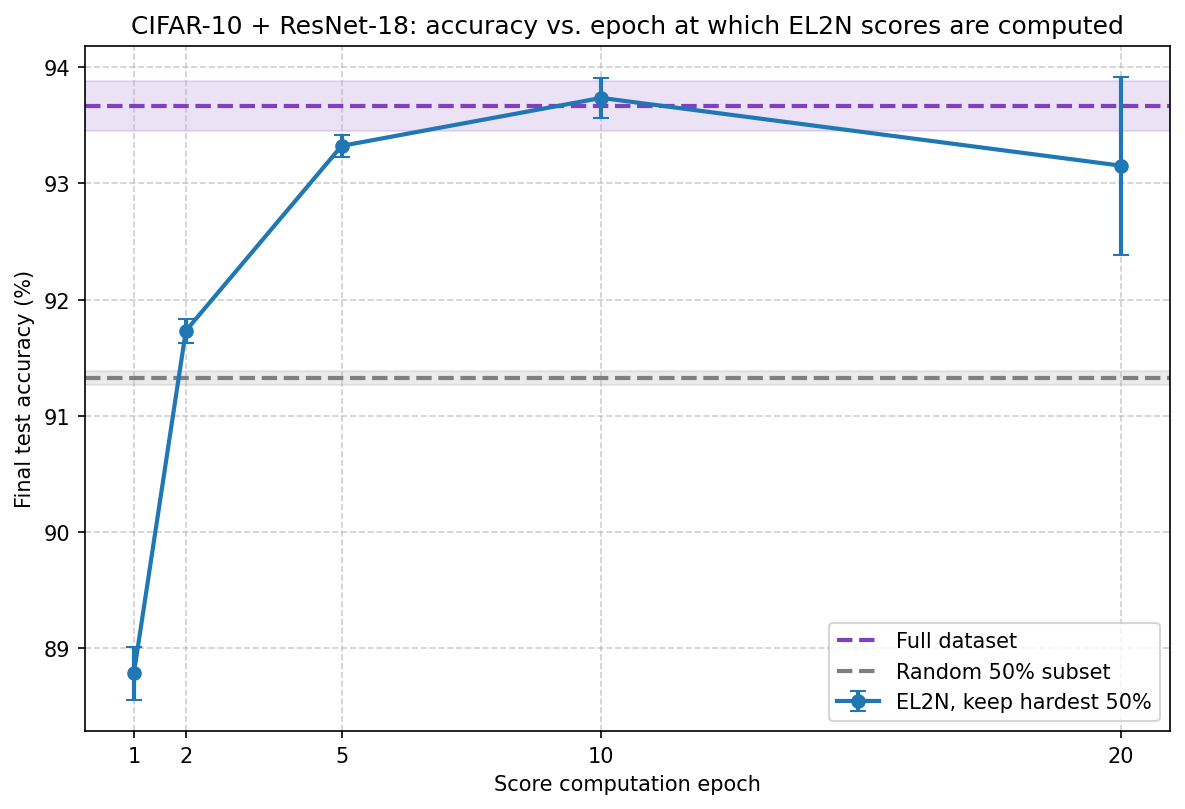

In [21]:
abl_rows = []
for ep in ABL_EPOCHS:
    m, sd = mean_std(ABL_RESULTS[('el2n_highest', ep, s)] for s in EVAL_SEEDS)
    abl_rows.append({'score_epoch': ep, 'mean': m, 'std': sd, 'n': len(EVAL_SEEDS)})
ABL_DF = pd.DataFrame(abl_rows)

assert ABL_KEEP in STEP2_RESULTS_DICT['random'], "Step 2 has no random baseline at this keep fraction"
full_m, full_sd = mean_std(STEP2_RESULTS_DICT['random'][1.0][s] for s in EVAL_SEEDS)
rand_m, rand_sd = mean_std(STEP2_RESULTS_DICT['random'][ABL_KEEP][s] for s in EVAL_SEEDS)
ABL_DF['full_mean'] = full_m
ABL_DF['random_mean'] = rand_m
ABL_DF.to_csv('step3_epoch_ablation.csv', index=False)
print(ABL_DF.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5.5), dpi=150)
ax.axhline(full_m, color=COLORS['full'], linestyle='--', linewidth=2, label='Full dataset')
ax.axhspan(full_m - full_sd, full_m + full_sd, color=COLORS['full'], alpha=0.15)
ax.axhline(rand_m, color=COLORS['random'], linestyle='--', linewidth=2, label=f'Random {int(ABL_KEEP * 100)}% subset')
ax.axhspan(rand_m - rand_sd, rand_m + rand_sd, color=COLORS['random'], alpha=0.15)
ax.errorbar(ABL_DF['score_epoch'], ABL_DF['mean'], yerr=ABL_DF['std'], fmt='o-', color=COLORS['el2n'],
            linewidth=2, capsize=4, label=f'EL2N, keep hardest {int(ABL_KEEP * 100)}%')
ax.set_xticks(ABL_EPOCHS)
ax.set_title('CIFAR-10 + ResNet-18: accuracy vs. epoch at which EL2N scores are computed')
ax.set_xlabel('Score computation epoch')
ax.set_ylabel('Final test accuracy (%)')
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(loc='lower right')
finish_figure(fig, 'step3_epoch_ablation.png')

## 4. Forgetting Score Baseline

In [22]:
FORGET_RUNS = 10
FORGET_SEEDS = [7000 + r * 1000 + 17 for r in range(FORGET_RUNS)]
FORGET_CKPT = 'forget_checkpoint.pt'
FORGET_FINAL = 'forget_scores.pt'
assert not set(FORGET_SEEDS) & (set(EVAL_SEEDS) | set(SCORE_SEEDS))


def train_for_forgetting(seed, data, targets, total_steps):
    seed_everything(seed)
    n = data.size(0)
    num_epochs = total_steps // STEPS_PER_EPOCH
    model = build_cifar_resnet18().to(DEVICE)
    optimizer = build_optimizer(model)
    milestones = [int(0.3 * total_steps), int(0.6 * total_steps), int(0.8 * total_steps)]
    scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=milestones, gamma=0.2)
    criterion = nn.CrossEntropyLoss()
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    prev_correct = torch.zeros(n, dtype=torch.bool, device=DEVICE)
    ever_correct = torch.zeros(n, dtype=torch.bool, device=DEVICE)
    events = torch.zeros(n, device=DEVICE)
    model.train()
    step = 0
    pbar = tqdm(total=total_steps, desc="Forgetting run", leave=False, mininterval=2)
    while step < total_steps:
        perm = torch.randperm(n, device=DEVICE)
        for i in range(0, n - BATCH_SIZE + 1, BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            inputs = gpu_augment(data[idx])
            y = targets[idx]
            optimizer.zero_grad(set_to_none=True)
            with amp():
                logits = model(inputs)
                loss = criterion(logits, y)
            correct = logits.argmax(dim=1) == y
            events[idx] = events[idx] + (prev_correct[idx] & ~correct).float()
            ever_correct[idx] = ever_correct[idx] | correct
            prev_correct[idx] = correct
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            step += 1
            pbar.update(1)
            if step % 200 == 0:
                pbar.set_postfix(loss=f"{loss.item():.3f}")
            if step >= total_steps:
                break
    pbar.close()
    events[~ever_correct] = float(num_epochs)
    return events.cpu()


def run_forgetting_scoring(data, targets):
    config = {'total_steps': TOTAL_STEPS, 'first_seed': FORGET_SEEDS[0]}
    if os.path.exists(FORGET_CKPT):
        state = torch.load(FORGET_CKPT, map_location='cpu', weights_only=False)
        assert state['config'] == config, f"{FORGET_CKPT} was made with different settings - move it away"
    else:
        state = {'config': config, 'per_run': []}
    done = min(len(state['per_run']), FORGET_RUNS)
    run_bar = tqdm(total=FORGET_RUNS, initial=done, desc="Step 5: forgetting scoring runs")
    durations = []
    for run in range(done, FORGET_RUNS):
        start = time.time()
        state['per_run'].append(train_for_forgetting(FORGET_SEEDS[run], data, targets, TOTAL_STEPS))
        torch.save(state, FORGET_CKPT)
        durations.append(time.time() - start)
        remaining = FORGET_RUNS - run - 1
        run_bar.update(1)
        run_bar.set_postfix(last_min=f"{durations[-1] / 60:.1f}", eta_min=f"{np.mean(durations) * remaining / 60:.0f}")
    run_bar.close()
    per_run = state['per_run'][:FORGET_RUNS]
    mean_scores = torch.stack(per_run).mean(dim=0)
    torch.save(mean_scores, FORGET_FINAL)
    return mean_scores, per_run


def select_by_score(scores, keep_fraction, highest, tiebreak_seed=0):
    n = len(scores)
    k = int(round(n * keep_fraction))
    g = torch.Generator()
    g.manual_seed(tiebreak_seed)
    key = scores.float() + 1e-3 * torch.rand(n, generator=g)
    return torch.argsort(key, descending=highest)[:k]


FORGET_SCORES, FORGET_PER_RUN = run_forgetting_scoring(TRAIN_DATA, TRAIN_TARGETS)
print(f"forgetting score | mean {FORGET_SCORES.mean():.3f} | max {FORGET_SCORES.max():.2f} | "
      f"share with mean score 0: {(FORGET_SCORES == 0).float().mean():.3f}")

Step 5: forgetting scoring runs:   0%|          | 0/10 [00:00<?, ?it/s]

Forgetting run:   0%|          | 0/19500 [00:00<?, ?it/s]

Forgetting run:   0%|          | 0/19500 [00:00<?, ?it/s]

Forgetting run:   0%|          | 0/19500 [00:00<?, ?it/s]

Forgetting run:   0%|          | 0/19500 [00:00<?, ?it/s]

...

Forgetting run:   0%|          | 0/19500 [00:00<?, ?it/s]

Forgetting run:   0%|          | 0/19500 [00:00<?, ?it/s]

Forgetting run:   0%|          | 0/19500 [00:00<?, ?it/s]

Forgetting run:   0%|          | 0/19500 [00:00<?, ?it/s]

forgetting score | mean 1.690 | max 10.00 | share with mean score 0: 0.094


In [23]:
FORGET_PATH = 'step5_forgetting_results.pt'
FORGET_CONFIG = {'total_steps': TOTAL_STEPS, 'runs': FORGET_RUNS}

forget_jobs = []
for seed in EVAL_SEEDS:
    for frac in [f for f in KEEP_FRACTIONS if f < 1.0]:
        indices = select_by_score(FORGET_SCORES, frac, highest=True)
        forget_jobs.append((('forget_highest', frac, seed), make_job(indices, TRAIN_TARGETS, seed)))

FORGET_RESULTS = run_jobs(forget_jobs, FORGET_PATH, FORGET_CONFIG, 'Step 5: forgetting-score retraining')

Step 5: forgetting-score retraining:   0%|          | 0/12 [00:00<?, ?it/s]

Retraining:   0%|          | 0/19500 [00:00<?, ?it/s]

Step 5: forgetting-score retraining | ('forget_highest', 0.9, 101) | test_acc=93.67% (8.6 min)


Retraining:   0%|          | 0/19500 [00:00<?, ?it/s]

Step 5: forgetting-score retraining | ('forget_highest', 0.7, 101) | test_acc=93.89% (8.6 min)


...

Step 5: forgetting-score retraining | ('forget_highest', 0.7, 303) | test_acc=93.63% (9.7 min)


Retraining:   0%|          | 0/19500 [00:00<?, ?it/s]

Step 5: forgetting-score retraining | ('forget_highest', 0.5, 303) | test_acc=93.34% (9.7 min)


Retraining:   0%|          | 0/19500 [00:00<?, ?it/s]

Step 5: forgetting-score retraining | ('forget_highest', 0.3, 303) | test_acc=83.33% (9.2 min)


 keep_fraction  pruned_fraction  el2n_mean  el2n_std  forget_mean  forget_std  random_mean  random_std
           0.9              0.1      93.73      0.21        93.40        0.39        93.31        0.42
           0.7              0.3      93.78      0.18        93.81        0.16        92.47        0.54
           0.5              0.5      93.74      0.17        93.53        0.17        91.32        0.06
           0.3              0.7      84.06      1.72        87.50        3.66        89.41        0.06


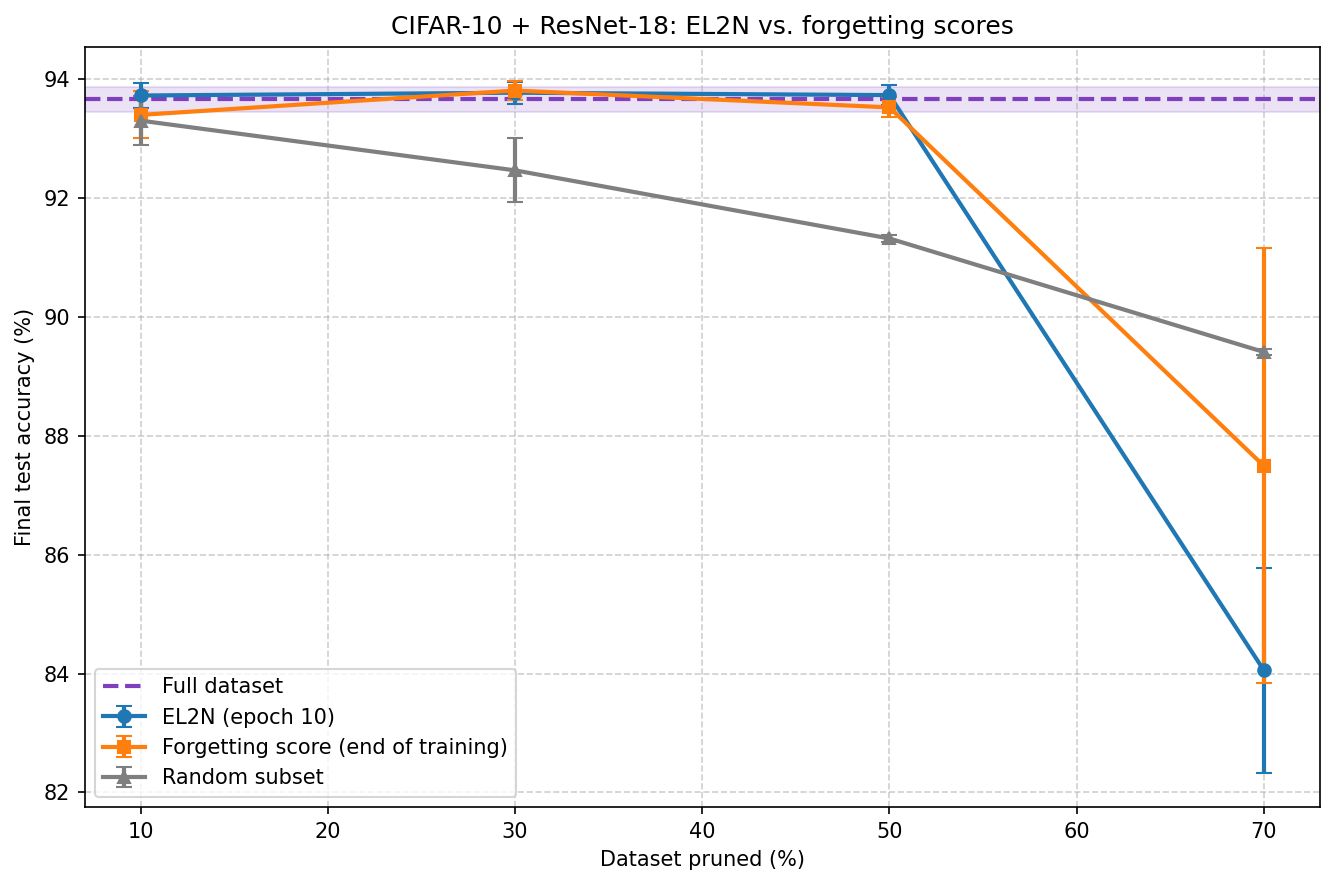

Spearman(EL2N epoch 10, forgetting) = 0.868
Spearman(EL2N epoch 20, forgetting) = 0.843


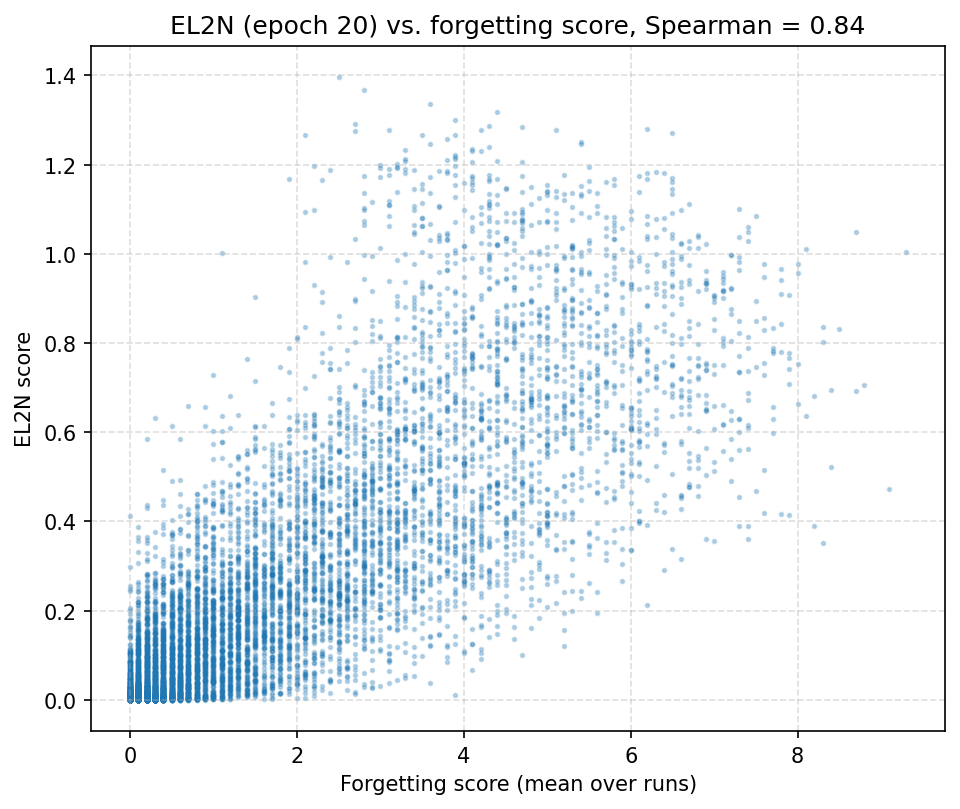

In [24]:
pruned_levels = [f for f in KEEP_FRACTIONS if f < 1.0]
cmp_rows = []
for frac in pruned_levels:
    row = {'keep_fraction': frac, 'pruned_fraction': round(1 - frac, 4)}
    row['el2n_mean'], row['el2n_std'] = mean_std(STEP2_RESULTS_DICT['el2n_highest'][frac][s] for s in EVAL_SEEDS)
    row['forget_mean'], row['forget_std'] = mean_std(FORGET_RESULTS[('forget_highest', frac, s)] for s in EVAL_SEEDS)
    row['random_mean'], row['random_std'] = mean_std(STEP2_RESULTS_DICT['random'][frac][s] for s in EVAL_SEEDS)
    cmp_rows.append(row)
CMP_DF = pd.DataFrame(cmp_rows)
CMP_DF.to_csv('step5_el2n_vs_forgetting.csv', index=False)
print(CMP_DF.round(2).to_string(index=False))

full_m, full_sd = mean_std(STEP2_RESULTS_DICT['random'][1.0][s] for s in EVAL_SEEDS)
x = CMP_DF['pruned_fraction'] * 100
fig, ax = plt.subplots(figsize=(9, 6), dpi=150)
ax.axhline(full_m, color=COLORS['full'], linestyle='--', linewidth=2, label='Full dataset')
ax.axhspan(full_m - full_sd, full_m + full_sd, color=COLORS['full'], alpha=0.15)
ax.errorbar(x, CMP_DF['el2n_mean'], yerr=CMP_DF['el2n_std'], fmt='o-', color=COLORS['el2n'], linewidth=2, capsize=4,
            label=f'EL2N (epoch {TARGET_SCORE_EPOCH})')
ax.errorbar(x, CMP_DF['forget_mean'], yerr=CMP_DF['forget_std'], fmt='s-', color=COLORS['forget'], linewidth=2, capsize=4,
            label='Forgetting score (end of training)')
ax.errorbar(x, CMP_DF['random_mean'], yerr=CMP_DF['random_std'], fmt='^-', color=COLORS['random'], linewidth=2, capsize=4,
            label='Random subset')
ax.set_title('CIFAR-10 + ResNet-18: EL2N vs. forgetting scores')
ax.set_xlabel('Dataset pruned (%)')
ax.set_ylabel('Final test accuracy (%)')
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(loc='lower left')
finish_figure(fig, 'step5_el2n_vs_forgetting.png')

late_epoch = SCORE_EPOCHS[-1]
rho_target = spearman(SCORES_DICT[TARGET_SCORE_EPOCH], FORGET_SCORES)
rho_late = spearman(SCORES_DICT[late_epoch], FORGET_SCORES)
print(f"Spearman(EL2N epoch {TARGET_SCORE_EPOCH}, forgetting) = {rho_target:.3f}")
print(f"Spearman(EL2N epoch {late_epoch}, forgetting) = {rho_late:.3f}")

pick = np.random.default_rng(0).choice(len(FORGET_SCORES), size=10000, replace=False)
fig, ax = plt.subplots(figsize=(6.5, 5.5), dpi=150)
ax.scatter(FORGET_SCORES.numpy()[pick], SCORES_DICT[late_epoch].numpy()[pick], s=3, alpha=0.25, color=COLORS['el2n'])
ax.set_title(f'EL2N (epoch {late_epoch}) vs. forgetting score, Spearman = {rho_late:.2f}')
ax.set_xlabel('Forgetting score (mean over runs)')
ax.set_ylabel('EL2N score')
ax.grid(True, linestyle='--', alpha=0.4)
finish_figure(fig, 'step5_score_scatter.png')

## 5. Label Noise Analysis

In [25]:
NOISE_FRACTION = 0.1
NOISE_KEEP = 0.4
NOISE_OFFSETS = [0.0, 0.2, 0.4, 0.5, 0.55, 0.58, 0.6]
NOISE_SEEDS = EVAL_SEEDS[:2]
NOISE_SCORE_EPOCH = 10
NOISE_LABEL_SEED = 2024
NOISE_SCORE_SEEDS = [30000 + r * 1000 + 7 for r in range(NUM_SCORE_RUNS)]
NOISE_CKPT = 'noise_scores_checkpoint.pt'
NOISE_FINAL = 'noise_scores.pt'

assert NOISE_SCORE_EPOCH in SCORES_DICT
assert all(o + NOISE_KEEP <= 1 + 1e-9 for o in NOISE_OFFSETS)
assert not set(NOISE_SCORE_SEEDS) & (set(EVAL_SEEDS) | set(SCORE_SEEDS) | set(globals().get('FORGET_SEEDS', [])))


def make_noisy_targets(targets, fraction, seed):
    g = torch.Generator()
    g.manual_seed(seed)
    clean = targets.cpu()
    n = clean.size(0)
    m = int(round(n * fraction))
    chosen = torch.randperm(n, generator=g)[:m]
    shuffled = torch.randperm(m, generator=g)
    noisy = clean.clone()
    noisy[chosen] = clean[chosen][shuffled]
    return noisy.to(DEVICE), (noisy != clean)


def score_run_noisy(seed, data, targets, max_epoch, epoch_bar):
    seed_everything(seed)
    model = build_cifar_resnet18().to(DEVICE)
    optimizer = build_optimizer(model)
    criterion = nn.CrossEntropyLoss()
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    n = data.size(0)
    epoch_bar.reset(total=max_epoch)
    for epoch in range(1, max_epoch + 1):
        model.train()
        perm = torch.randperm(n, device=DEVICE)
        loss_sum = torch.zeros((), device=DEVICE)
        for i in range(0, n - BATCH_SIZE + 1, BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            inputs = gpu_augment(data[idx])
            y = targets[idx]
            optimizer.zero_grad(set_to_none=True)
            with amp():
                loss = criterion(model(inputs), y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            loss_sum += loss.detach()
        epoch_bar.set_postfix(loss=f"{loss_sum.item() / STEPS_PER_EPOCH:.4f}")
        epoch_bar.update(1)
    return compute_el2n_scores(model, data, targets)


def run_noisy_scoring(data, targets):
    config = {'label_seed': NOISE_LABEL_SEED, 'fraction': NOISE_FRACTION, 'epoch': NOISE_SCORE_EPOCH,
              'first_seed': NOISE_SCORE_SEEDS[0]}
    if os.path.exists(NOISE_CKPT):
        state = torch.load(NOISE_CKPT, map_location='cpu', weights_only=False)
        assert state['config'] == config, f"{NOISE_CKPT} was made with different settings - move it away"
    else:
        state = {'config': config, 'per_run': []}
    done = len(state['per_run'])
    run_bar = tqdm(total=NUM_SCORE_RUNS, initial=done, desc="Step 6: noisy-label scoring runs")
    epoch_bar = tqdm(total=NOISE_SCORE_EPOCH, desc="Epochs", leave=False)
    durations = []
    for run in range(done, NUM_SCORE_RUNS):
        start = time.time()
        state['per_run'].append(score_run_noisy(NOISE_SCORE_SEEDS[run], data, targets, NOISE_SCORE_EPOCH, epoch_bar))
        torch.save(state, NOISE_CKPT)
        durations.append(time.time() - start)
        remaining = NUM_SCORE_RUNS - run - 1
        run_bar.update(1)
        run_bar.set_postfix(last_min=f"{durations[-1] / 60:.1f}", eta_min=f"{np.mean(durations) * remaining / 60:.0f}")
    epoch_bar.close()
    run_bar.close()
    mean_scores = torch.stack(state['per_run']).mean(dim=0)
    torch.save(mean_scores, NOISE_FINAL)
    return mean_scores


def window_indices(scores, offset, keep):
    n = len(scores)
    start = int(round(n * offset))
    k = int(round(n * keep))
    order = torch.argsort(scores)
    return order[start:start + k]


NOISY_TARGETS, NOISE_CORRUPTED = make_noisy_targets(TRAIN_TARGETS, NOISE_FRACTION, NOISE_LABEL_SEED)
print(f"labels actually changed: {int(NOISE_CORRUPTED.sum())} of {len(NOISE_CORRUPTED)}")
NOISE_SCORES = run_noisy_scoring(TRAIN_DATA, NOISY_TARGETS)

labels actually changed: 4503 of 50000


Step 6: noisy-label scoring runs:   0%|          | 0/10 [00:00<?, ?it/s]

Epochs:   0%|          | 0/10 [00:00<?, ?it/s]

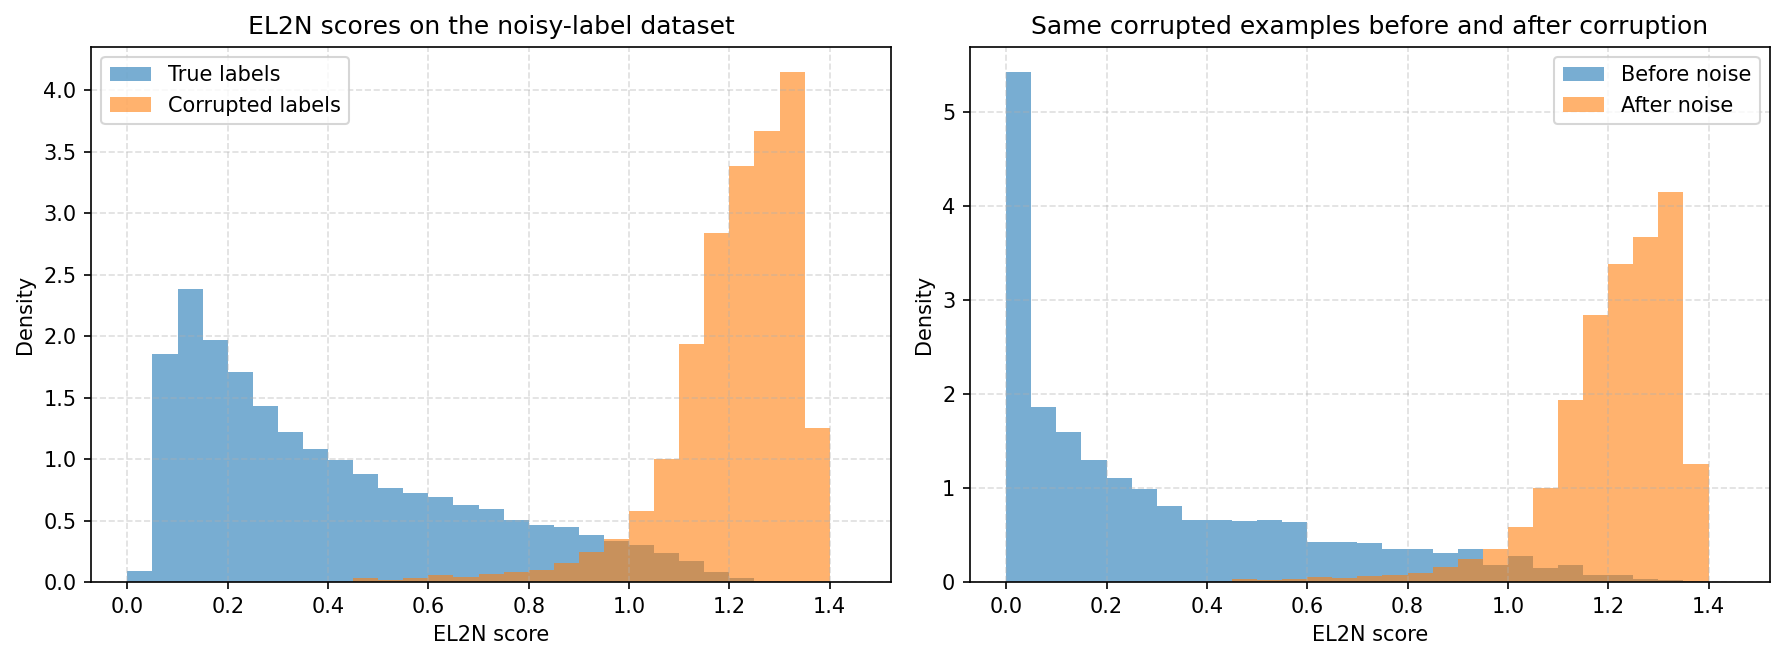

corrupted examples: 4503
share of corrupted among the 4503 highest EL2N scores: 0.855
mean EL2N | true labels 0.404 | corrupted 1.211 | same examples before noise 0.305


In [26]:
corrupted = NOISE_CORRUPTED.numpy()
noisy_s = NOISE_SCORES.numpy()
clean_s = SCORES_DICT[NOISE_SCORE_EPOCH].numpy()
bins = np.linspace(0, 1.45, 30)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), dpi=150)
axes[0].hist(noisy_s[~corrupted], bins=bins, density=True, alpha=0.6, color=COLORS['el2n'], label='True labels')
axes[0].hist(noisy_s[corrupted], bins=bins, density=True, alpha=0.6, color=COLORS['forget'], label='Corrupted labels')
axes[0].set_title('EL2N scores on the noisy-label dataset')
axes[1].hist(clean_s[corrupted], bins=bins, density=True, alpha=0.6, color=COLORS['el2n'], label='Before noise')
axes[1].hist(noisy_s[corrupted], bins=bins, density=True, alpha=0.6, color=COLORS['forget'], label='After noise')
axes[1].set_title('Same corrupted examples before and after corruption')
for ax in axes:
    ax.set_xlabel('EL2N score')
    ax.set_ylabel('Density')
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.4)
finish_figure(fig, 'step6_noise_score_histograms.png')

n_corrupted = int(corrupted.sum())
top = torch.argsort(NOISE_SCORES, descending=True)[:n_corrupted]
precision = float(NOISE_CORRUPTED[top].float().mean())
print(f"corrupted examples: {n_corrupted}")
print(f"share of corrupted among the {n_corrupted} highest EL2N scores: {precision:.3f}")
print(f"mean EL2N | true labels {noisy_s[~corrupted].mean():.3f} | corrupted {noisy_s[corrupted].mean():.3f} | "
      f"same examples before noise {clean_s[corrupted].mean():.3f}")

## 6. Finalising the results

          epoch 1  epoch 2  epoch 5  epoch 10  epoch 20
epoch 1     1.000    0.854    0.607     0.509     0.446
epoch 2     0.854    1.000    0.801     0.670     0.622
epoch 5     0.607    0.801    1.000     0.877     0.815
epoch 10    0.509    0.670    0.877     1.000     0.876
epoch 20    0.446    0.622    0.815     0.876     1.000


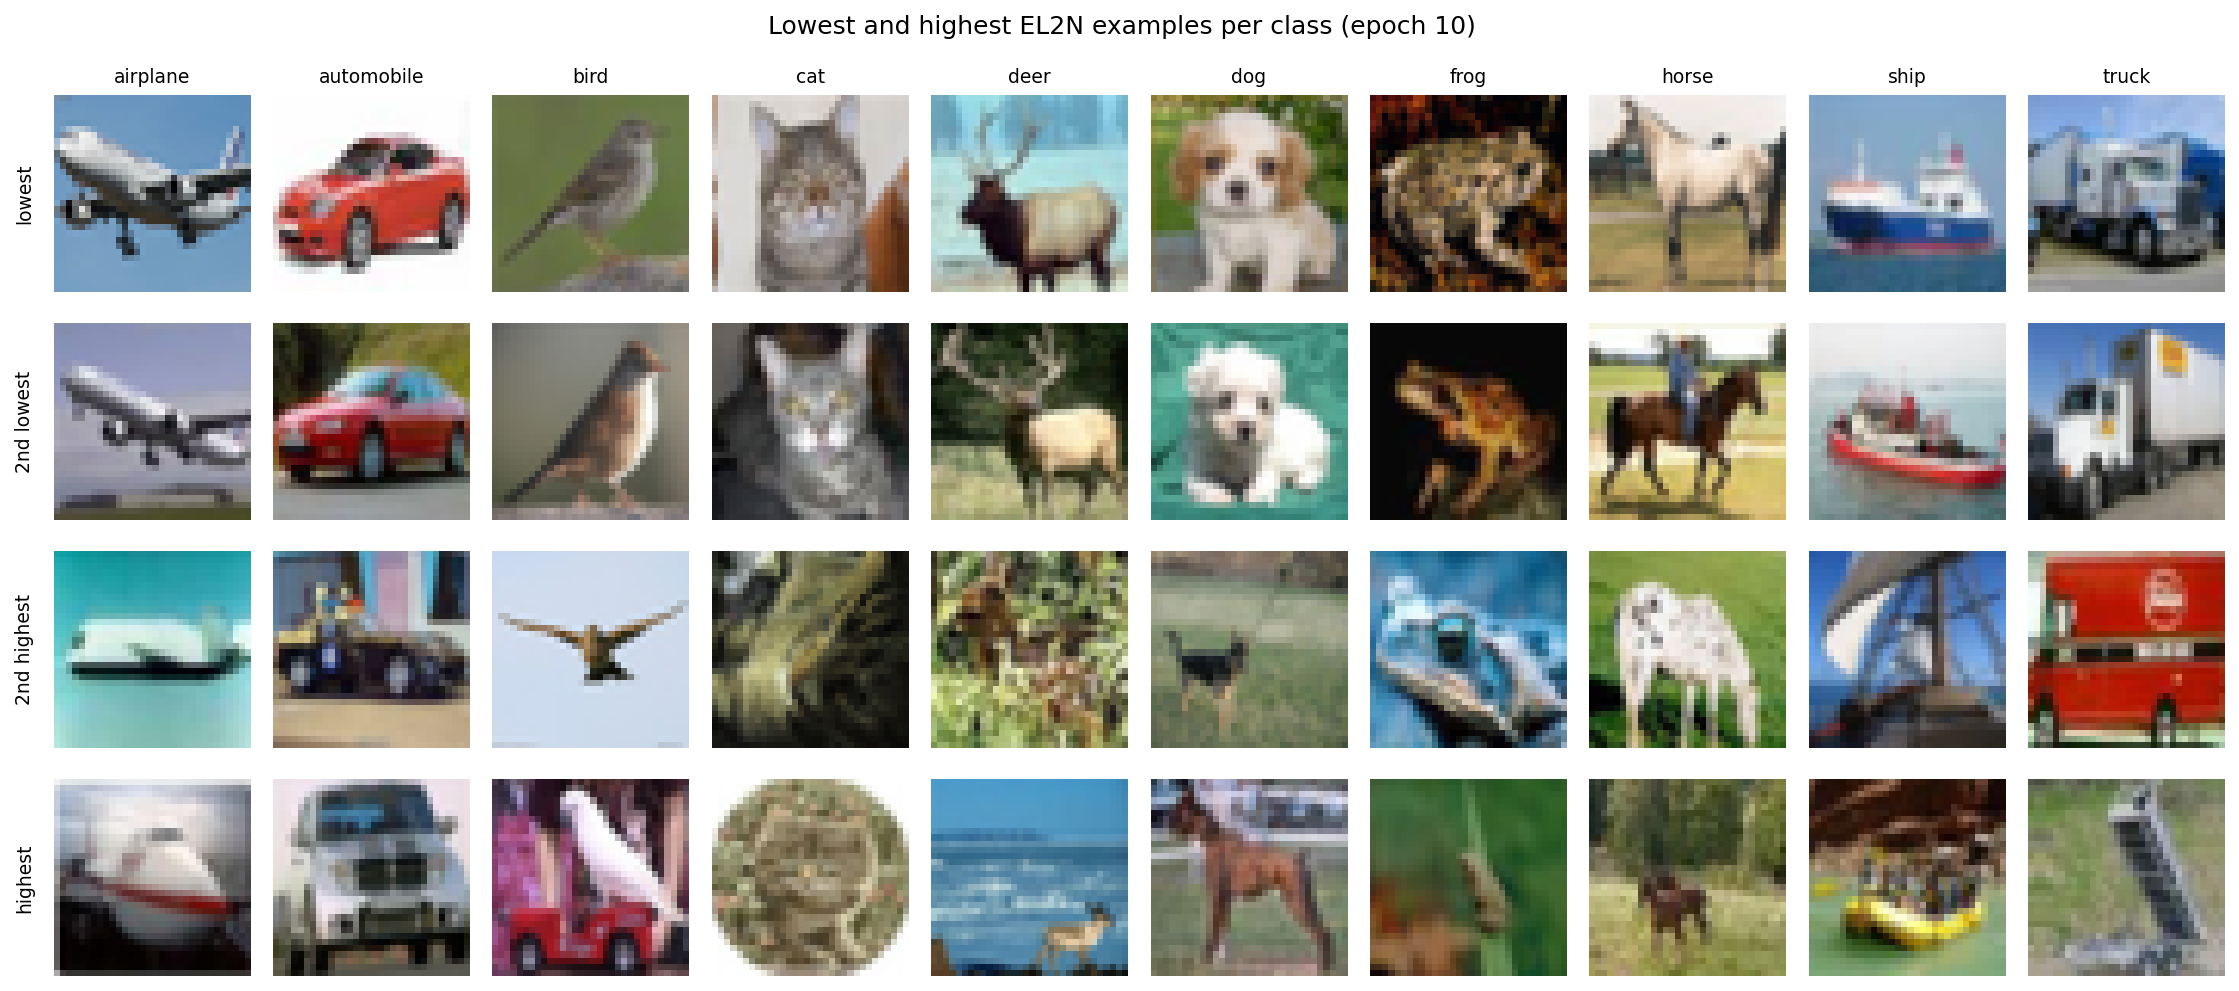

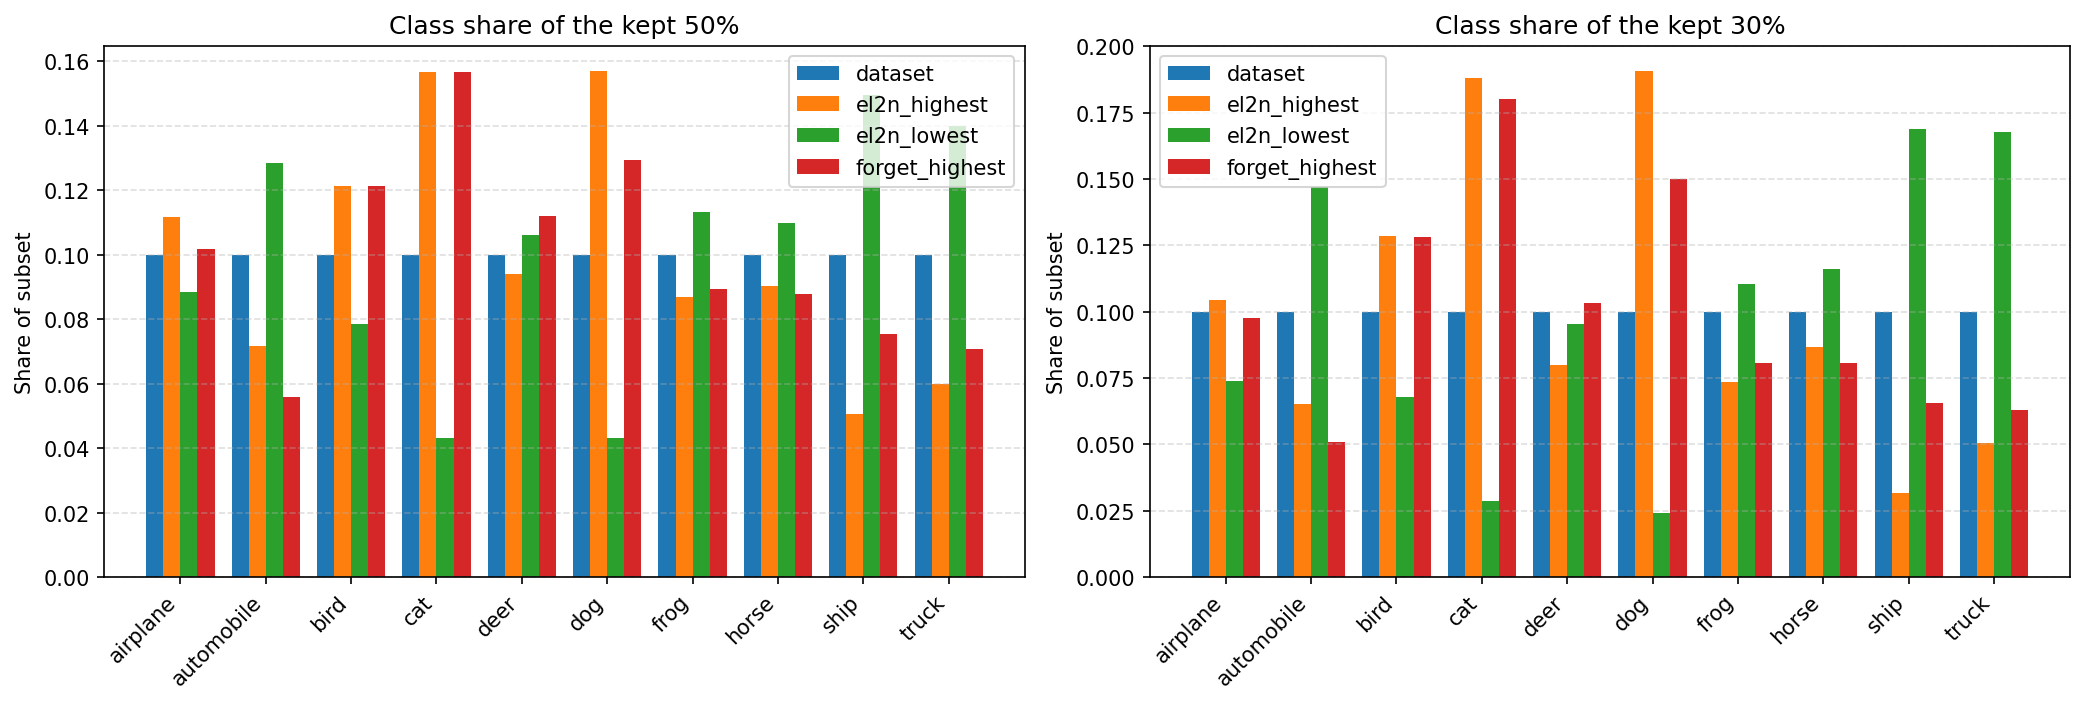

In [27]:
ranks = {e: pd.Series(SCORES_DICT[e].numpy()).rank() for e in SCORE_EPOCHS}
RANK_DF = pd.DataFrame([[float(ranks[a].corr(ranks[b])) for b in SCORE_EPOCHS] for a in SCORE_EPOCHS],
                       index=[f'epoch {e}' for e in SCORE_EPOCHS], columns=[f'epoch {e}' for e in SCORE_EPOCHS])
RANK_DF.to_csv('step7_epoch_rank_correlation.csv')
print(RANK_DF.round(3).to_string())

MEAN = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
STD = torch.tensor([0.2023, 0.1994, 0.2010]).view(3, 1, 1)
img_scores = SCORES_DICT[TARGET_SCORE_EPOCH]
labels_cpu = TRAIN_TARGETS.cpu()
rows = [('lowest', 0), ('2nd lowest', 1), ('2nd highest', -2), ('highest', -1)]
fig, axes = plt.subplots(len(rows), 10, figsize=(15, 6.8), dpi=150)
for c in range(10):
    class_idx = (labels_cpu == c).nonzero().squeeze(1)
    order = class_idx[torch.argsort(img_scores[class_idx])]
    for r, (name, pos) in enumerate(rows):
        image = TRAIN_DATA[int(order[pos])].cpu() * STD + MEAN
        axes[r, c].imshow(image.clamp(0, 1).permute(1, 2, 0).numpy())
        axes[r, c].axis('off')
        if c == 0:
            axes[r, c].text(-0.1, 0.5, name, transform=axes[r, c].transAxes, rotation=90, va='center', ha='right', fontsize=9)
    axes[0, c].set_title(CLASS_NAMES[c], fontsize=9)
fig.suptitle(f'Lowest and highest EL2N examples per class (epoch {TARGET_SCORE_EPOCH})')
finish_figure(fig, 'step7_example_images.png')

labels_np = labels_cpu.numpy()
levels = sorted({f for f in [0.5, min(f for f in KEEP_FRACTIONS if f < 1.0)] if f in KEEP_FRACTIONS and f < 1.0}, reverse=True)
comp_rows = []
fig, axes = plt.subplots(1, len(levels), figsize=(7 * len(levels), 4.8), dpi=150, squeeze=False)
for ax, frac in zip(axes[0], levels):
    groups = {'dataset': np.bincount(labels_np, minlength=10) / len(labels_np)}
    for strategy in ['el2n_highest', 'el2n_lowest']:
        idx = get_pruned_indices(img_scores, frac, strategy, 0).numpy()
        groups[strategy] = np.bincount(labels_np[idx], minlength=10) / len(idx)
    if 'FORGET_SCORES' in globals():
        idx = select_by_score(FORGET_SCORES, frac, highest=True).numpy()
        groups['forget_highest'] = np.bincount(labels_np[idx], minlength=10) / len(idx)
    width = 0.8 / len(groups)
    for g_i, (name, shares) in enumerate(groups.items()):
        ax.bar(np.arange(10) + g_i * width, shares, width=width, label=name)
        comp_rows.append({'keep_fraction': frac, 'subset': name, **{CLASS_NAMES[c]: float(shares[c]) for c in range(10)}})
    ax.set_xticks(np.arange(10) + 0.4 - width / 2)
    ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right')
    ax.set_title(f'Class share of the kept {int(frac * 100)}%')
    ax.set_ylabel('Share of subset')
    ax.legend()
    ax.grid(True, axis='y', linestyle='--', alpha=0.4)
pd.DataFrame(comp_rows).to_csv('step7_class_composition.csv', index=False)
finish_figure(fig, 'step7_class_composition.png')

In [28]:


raw_rows = []
for method, by_frac in STEP2_RESULTS_DICT.items():
    for frac, by_seed in by_frac.items():
        if frac >= 1.0 and method != 'random':
            continue
        name = 'full' if frac >= 1.0 else method
        for seed, acc in by_seed.items():
            raw_rows.append({'experiment': 'step2', 'method': name, 'keep_fraction': frac, 'seed': seed, 'test_acc': acc})
for (method, ep, seed), acc in ABL_RESULTS.items():
    raw_rows.append({'experiment': 'step3', 'method': f'el2n_highest_epoch{ep}', 'keep_fraction': ABL_KEEP, 'seed': seed, 'test_acc': acc})
for (method, frac, seed), acc in FORGET_RESULTS.items():
    raw_rows.append({'experiment': 'step5', 'method': method, 'keep_fraction': frac, 'seed': seed, 'test_acc': acc})
RAW_DF = pd.DataFrame(raw_rows)
RAW_DF.to_csv('all_runs.csv', index=False)

full_by_seed = STEP2_RESULTS_DICT['random'][1.0]
pair_rows = []
for frac in [f for f in KEEP_FRACTIONS if f < 1.0]:
    comparisons = {
        'el2n_highest - full': [STEP2_RESULTS_DICT['el2n_highest'][frac][s] - full_by_seed[s] for s in EVAL_SEEDS],
        'el2n_highest - random': [STEP2_RESULTS_DICT['el2n_highest'][frac][s] - STEP2_RESULTS_DICT['random'][frac][s] for s in EVAL_SEEDS],
        'forget_highest - full': [FORGET_RESULTS[('forget_highest', frac, s)] - full_by_seed[s] for s in EVAL_SEEDS],
        'el2n_highest - forget_highest': [STEP2_RESULTS_DICT['el2n_highest'][frac][s] - FORGET_RESULTS[('forget_highest', frac, s)] for s in EVAL_SEEDS],
    }
    for name, diffs in comparisons.items():
        m, sd = mean_std(diffs)
        pair_rows.append({'keep_fraction': frac, 'comparison': name, 'mean_diff': m, 'std_diff': sd, 'n': len(diffs)})
PAIR_DF = pd.DataFrame(pair_rows)
PAIR_DF.to_csv('paired_differences.csv', index=False)
print(PAIR_DF.round(2).to_string(index=False))

RUN_CONFIG = {
    'torch': torch.__version__, 'torchvision': torchvision.__version__, 'python': platform.python_version(),
    'gpu': torch.cuda.get_device_name(0) if USE_AMP else 'cpu', 'amp': USE_AMP,
    'batch_size': BATCH_SIZE, 'retrain_epochs_equiv': RETRAIN_EPOCHS_EQUIV, 'total_steps': TOTAL_STEPS,
    'keep_fractions': KEEP_FRACTIONS, 'eval_seeds': EVAL_SEEDS, 'score_seeds': SCORE_SEEDS,
    'score_epochs': SCORE_EPOCHS, 'target_score_epoch': TARGET_SCORE_EPOCH,
    'forget_runs': FORGET_RUNS, 'noise_fraction': NOISE_FRACTION, 'noise_label_seed': NOISE_LABEL_SEED,
    'scoring_cost_epochs': {
        'el2n_as_run': NUM_SCORE_RUNS * SCORE_MAX_EPOCHS,
        'el2n_until_target_epoch': NUM_SCORE_RUNS * TARGET_SCORE_EPOCH,
        'forgetting': FORGET_RUNS * RETRAIN_EPOCHS_EQUIV,
    },
    'key_numbers': {
        'spearman_el2n_target_vs_forgetting': rho_target,
        'spearman_el2n_late_vs_forgetting': rho_late,
        'noise_top_share_corrupted': precision,
        'noise_mean_el2n_true_labels': float(noisy_s[~corrupted].mean()),
        'noise_mean_el2n_corrupted': float(noisy_s[corrupted].mean()),
        'noise_mean_el2n_corrupted_before_noise': float(clean_s[corrupted].mean()),
    },
}
with open('run_config.json', 'w') as f:
    json.dump(RUN_CONFIG, f, indent=2)
print(json.dumps(RUN_CONFIG, indent=2))

 keep_fraction                    comparison  mean_diff  std_diff  n
           0.9           el2n_highest - full       0.07      0.14  3
           0.9         el2n_highest - random       0.42      0.59  3
           0.9         forget_highest - full      -0.26      0.22  3
           0.9 el2n_highest - forget_highest       0.33      0.35  3
           0.7           el2n_highest - full       0.11      0.39  3
           0.7         el2n_highest - random       1.31      0.52  3
           0.7         forget_highest - full       0.15      0.13  3
           0.7 el2n_highest - forget_highest      -0.04      0.30  3
           0.5           el2n_highest - full       0.07      0.31  3
           0.5         el2n_highest - random       2.41      0.22  3
           0.5         forget_highest - full      -0.13      0.14  3
           0.5 el2n_highest - forget_highest       0.21      0.32  3
           0.3           el2n_highest - full      -9.61      1.89  3
           0.3         el2n_highes

In [29]:
artifacts = ['step2_summary.csv', 'step2_pruning_curve.png',
             'step3_epoch_ablation.csv', 'step3_epoch_ablation.png',
             'step5_el2n_vs_forgetting.csv', 'step5_el2n_vs_forgetting.png', 'step5_score_scatter.png',
             'step6_noise_score_histograms.png',
             'step7_epoch_rank_correlation.csv', 'step7_example_images.png',
             'step7_class_composition.csv', 'step7_class_composition.png',
             'all_runs.csv', 'paired_differences.csv', 'run_config.json']
for name in artifacts:
    print(f"{'ok     ' if os.path.exists(name) else 'MISSING'} {name}")

ok      step2_summary.csv
ok      step2_pruning_curve.png
ok      step3_epoch_ablation.csv
ok      step3_epoch_ablation.png
ok      step5_el2n_vs_forgetting.csv
ok      step5_el2n_vs_forgetting.png
ok      step5_score_scatter.png
ok      step6_noise_score_histograms.png
ok      step7_epoch_rank_correlation.csv
ok      step7_example_images.png
ok      step7_class_composition.csv
ok      step7_class_composition.png
ok      all_runs.csv
ok      paired_differences.csv
ok      run_config.json
